# Ultrashort pulses through lenses, prisms and gratings

A pulse of 20 fs at 800 nm has a spectrum about 50 nm wide, and every
optical element treats each of its colours a little differently. For a
continuous wave laser only the phase of the light at one frequency
matters; for a femtosecond pulse it is how that phase changes over the
spectrum. Its first derivative is the group delay, the arrival time of the
pulse; its second derivative, the group delay dispersion (GDD), stretches
the pulse. Neither shows up in the phase fronts, so a lens that focuses a
continuous wave perfectly can still smear a pulse in space and time.

This notebook goes through the three classic effects with the tools of
`pyoptics.ultrafast`, each against its closed form:

1. **GDD from the glass catalogue.** Group index, group velocity
   dispersion and third order dispersion from the Sellmeier formulas of
   `pyoptics.glasses`; the broadening of pulses in 10 mm of glass, exact
   numerics against the Gaussian formula
   $\tau_\text{out} = \tau\sqrt{1 + (4\ln 2\,\text{GDD}/\tau^2)^2}$, and
   where third order dispersion breaks it.
2. **Bor's pulse-front delay.** Behind a lens the pulse travels with the
   group velocity, the phase fronts with the phase velocity. The pulse
   front lags behind the phase front, most on the axis where the glass is
   thickest, by $\Delta T(r) = -\frac{r^2}{2c}\lambda\frac{dP}{d\lambda}$.
   Group delays summed along traced rays (`ray_delays()`) against Bor's
   formula, for an aspheric singlet and an achromat designed for 800 nm.
3. **The focus in space and time.** The focal field of a pulse is a sum
   of monochromatic focuses: the lenses traced at 160 wavelengths
   (`focal_spectrum()`) and summed into $x$–$t$ maps of the focus, with
   and without a compensation of the axial GDD. The singlet's focus on the
   axis is the box average of Bor and Horváth.
4. **Pulse-front tilt.** Behind a prism or a grating the colours leave at
   different angles, and the pulse front is tilted against the phase
   fronts by $\tan\gamma = \lambda\,d\theta/d\lambda$: group delays of rays
   through a prism, and $x$–$t$ maps built from the dispersed spectrum.
5. **Bonus: simultaneous spatial and temporal focusing.** A spatially
   chirped beam is short only in the focus, where all its colours overlap:
   the axial pulse duration against a closed form, and the axial
   confinement compared with a normal focus.

Units: lengths in mm (µm in the focus), times in fs, wavelengths in nm.
Fields follow the pyoptics convention $\exp(i(kz - \omega t))$: a slab
multiplies the spectrum by $\exp(i\omega n L/c)$ and the envelope is
$E(t) = \int E(\omega)\,e^{-i(\omega - \omega_0)t}\,d\omega/2\pi$
(`to_time()`).

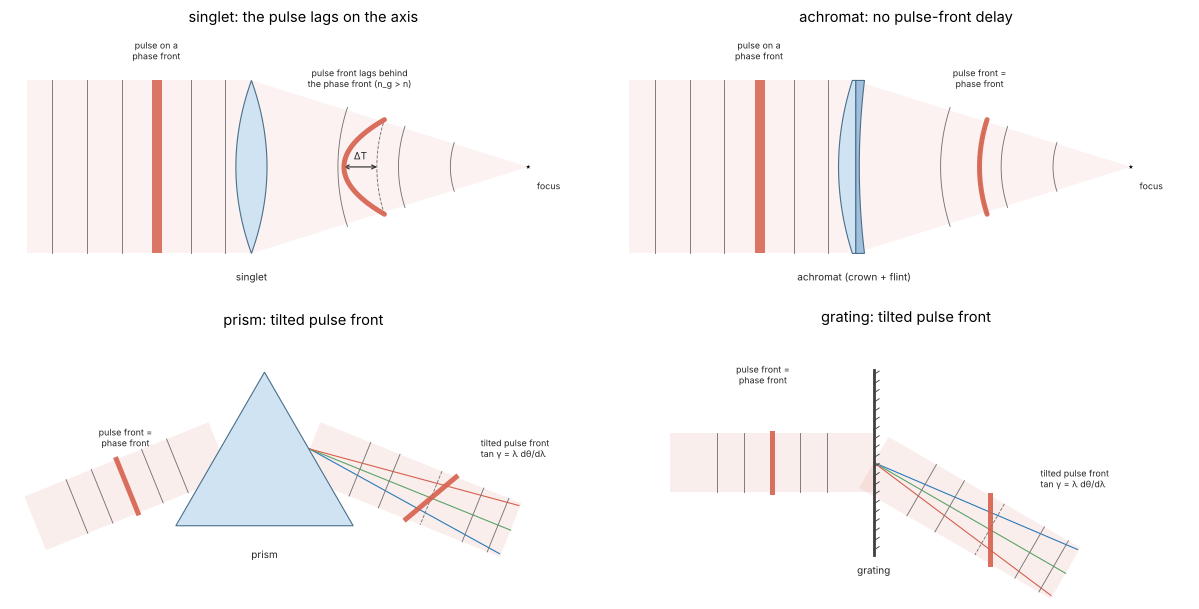

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from pyoptics import glasses as gl
from pyoptics import raytrace as rt
from pyoptics import lens_optimization as lo
from pyoptics import ultrafast as uf
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#7b5cc4", "0.45"
t_start = time.time()
WL = 800.0                                   # centre wavelength (nm)
C = uf.C_MM_PER_FS                           # speed of light in mm/fs
OM0 = float(uf.omega_from_wavelength(WL))
bk7, sf6, sf11 = gl.get("N-BK7", "schott"), gl.get("N-SF6", "schott"), gl.get("N-SF11", "schott")

fig, ax = plt.subplots(2, 2, figsize=(15, 7.5), layout="constrained")
sketch.pulse_through_lens(ax[0, 0], title="singlet: the pulse lags on the axis")
sketch.pulse_through_lens(ax[0, 1], achromat=True, title="achromat: no pulse-front delay")
sketch.pulse_front_tilt(ax[1, 0], "prism", title="prism: tilted pulse front")
sketch.pulse_front_tilt(ax[1, 1], "grating", title="grating: tilted pulse front")
plt.show()

## 1. Dispersion of glasses and the broadening of a pulse

### Group index, GVD and TOD from the catalogue

A wave packet centred at $\omega_0$ travels with the group velocity
$c/n_g$, $n_g = n - \lambda\,dn/d\lambda$, and its frequencies spread
apart at the rate of the group velocity dispersion

$$\text{GVD} = \frac{d^2k}{d\omega^2} = \frac{\lambda^3}{2\pi c^2}\frac{d^2n}{d\lambda^2},
\qquad \text{TOD} = \frac{d^3k}{d\omega^3} = -\frac{\lambda^4}{4\pi^2c^3}\left(3\frac{d^2n}{d\lambda^2} + \lambda\frac{d^3n}{d\lambda^3}\right)$$

per length. `uf.group_index()`, `uf.gvd()` and `uf.tod()` take the
derivatives of any dispersion formula with five point differences; the
Sellmeier formulas come from the vendor catalogues (notebook 61), fused
silica and CaF₂ from Malitson's fits (`uf.FUSED_SILICA`, `uf.CAF2`). The
reference values are those of refractiveindex.info for the same formulas.

        glass        n      n_g  GVD (fs²/mm)   ref.  TOD (fs³/mm)
 fused silica  1.45332  1.46714         36.16  36.16         27.50
         CaF2  1.43053  1.43890         27.87      -         16.34
        N-BK7  1.51078  1.52665         44.65  44.65         32.10
        N-SF6  1.78433  1.83280        195.65      -        128.41
       N-SF11  1.76462  1.81149        187.50 187.50        124.01
zero dispersion wavelength of fused silica: 1273 nm (literature 1270 nm)


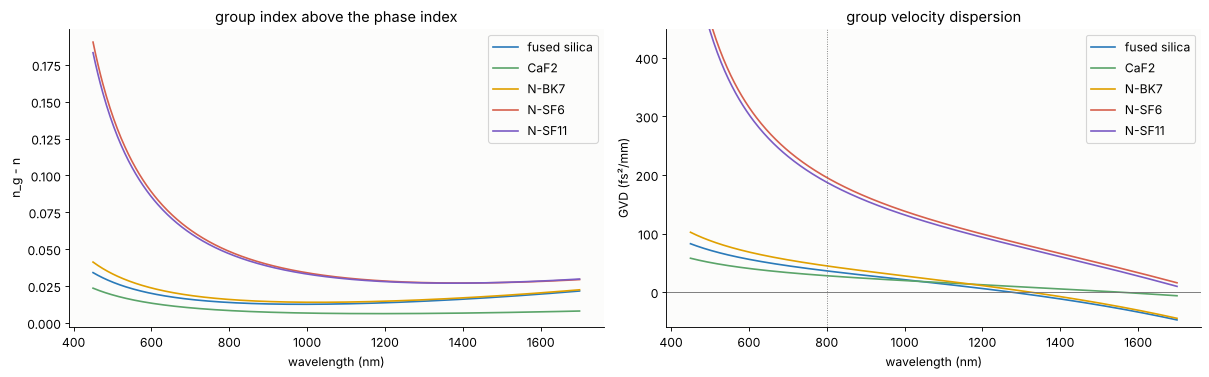

In [2]:
glasses = {"fused silica": uf.FUSED_SILICA, "CaF2": uf.CAF2, "N-BK7": bk7, "N-SF6": sf6,
           "N-SF11": sf11}
literature = {"fused silica": 36.16, "N-BK7": 44.65, "N-SF11": 187.5}   # fs²/mm at 800 nm
print(f"{'glass':>13} {'n':>8} {'n_g':>8} {'GVD (fs²/mm)':>13} {'ref.':>6} {'TOD (fs³/mm)':>13}")
for name, g in glasses.items():
    ref = f"{literature[name]:6.2f}" if name in literature else "     -"
    print(f"{name:>13} {float(g(WL)):8.5f} {float(uf.group_index(g, WL)):8.5f} "
          f"{float(uf.gvd(g, WL)):13.2f} {ref} {float(uf.tod(g, WL)):13.2f}")

lam = np.linspace(450, 1700, 400)
zd = brentq(lambda l: uf.gvd(uf.FUSED_SILICA, l), 1100, 1500)
print(f"zero dispersion wavelength of fused silica: {zd:.0f} nm (literature 1270 nm)")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
cols = dict(zip(glasses, [BLUE, GREEN, ORANGE, RED, PURPLE]))
for name, g in glasses.items():
    ax[0].plot(lam, uf.group_index(g, lam) - g(lam), color=cols[name], label=name)
    ax[1].plot(lam, uf.gvd(g, lam), color=cols[name], label=name)
ax[0].set_ylabel("n_g - n"); ax[0].set_title("group index above the phase index")
ax[1].axhline(0, color=GREY, lw=0.8); ax[1].axvline(WL, color=GREY, lw=0.8, ls=":")
ax[1].set_ylabel("GVD (fs²/mm)"); ax[1].set_title("group velocity dispersion"); ax[1].set_ylim(-60, 450)
for a in ax:
    a.set_xlabel("wavelength (nm)"); a.legend()
plt.show()

The group index is larger than the phase index by 1 to 3 %, so in glass
the pulse falls behind its own phase fronts by about 50 fs per mm (N-BK7)
to 150 fs per mm (N-SF11). That difference is the origin of Bor's effect in
section 2. The GVD of the dense flints is four times that of the crowns,
which makes achromats (crown plus flint) much more dispersive than
singlets. In the infrared beyond 1.27 µm fused silica has anomalous
dispersion, the basis of soliton fibre lasers.

### Broadening of a Gaussian pulse

A transform-limited Gaussian pulse of FWHM $\tau$ that acquires the
spectral phase $\tfrac12\text{GDD}\,(\omega - \omega_0)^2$ stays Gaussian
and is stretched to

$$\tau_\text{out} = \tau\sqrt{1 + \left(\frac{4\ln 2\,\text{GDD}}{\tau^2}\right)^2},$$

with the shortest output, $\sqrt2$ times the input, for
$\tau = \sqrt{4\ln2\,|\text{GDD}|}$ (`uf.gaussian_broadening()`,
`uf.optimal_input_duration()`). Very short pulses are stretched in
proportion to $1/\tau$: their bandwidth is large. The numerics below use the
exact phase $\omega n(\omega) L/c$ of a 10 mm slab (`uf.material_phase()`,
all orders) on a grid of 2048 frequencies from 590 to 1240 nm.

 fused silica: GDD    362 fs², best input  31.7 fs ->  44.8 fs; numerics vs formula: 0.11 % (tau >= 20 fs), 1.1 % at 5 fs


        N-BK7: GDD    447 fs², best input  35.2 fs ->  49.8 fs; numerics vs formula: 0.09 % (tau >= 20 fs), 1.0 % at 5 fs


       N-SF11: GDD   1875 fs², best input  72.1 fs -> 102.0 fs; numerics vs formula: 0.09 % (tau >= 20 fs), 1.5 % at 5 fs
7 fs pulse, 10 mm N-BK7 with compensated GDD: FWHM 10.2 fs


7 fs pulse, 10 mm N-SF11 with compensated GDD: FWHM 14.7 fs


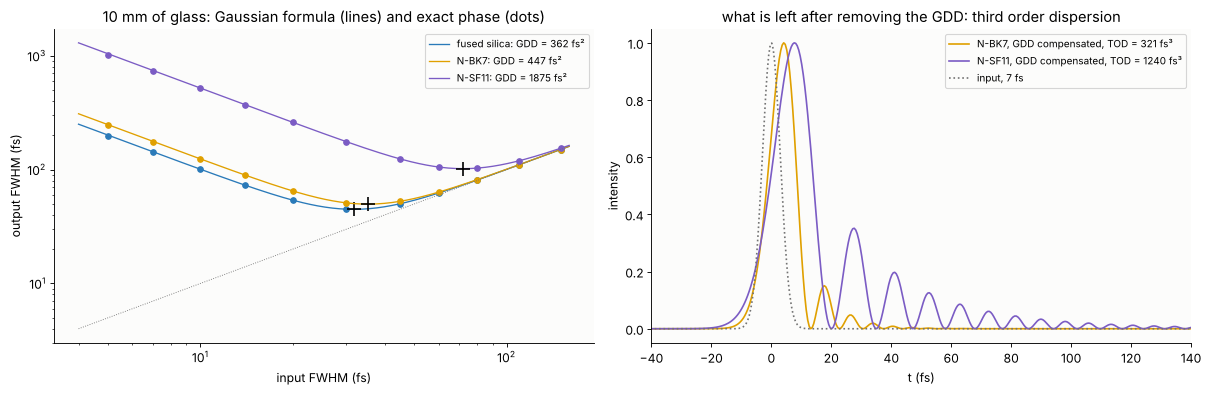

In [3]:
L_SLAB = 10.0
t_g, om = uf.pulse_grid(WL, 6000.0, 2048)          # 590 to 1240 nm
tt = np.linspace(-1500, 1500, 6001)
taus = np.array([5, 7, 10, 14, 20, 30, 45, 60, 80, 110, 150])


def through_slab(g, tau, length=L_SLAB):
    E = uf.gaussian_spectrum(om, OM0, tau)*np.exp(1j*uf.material_phase(g, om, length, OM0))
    return np.abs(uf.to_time(E, om, tt, OM0))**2


fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
for name in ("fused silica", "N-BK7", "N-SF11"):
    g = glasses[name]
    gdd = float(uf.gvd(g, WL))*L_SLAB
    num = np.array([uf.fwhm(tt, through_slab(g, tau)) for tau in taus])
    tf = np.geomspace(4, 160, 200)
    ax[0].loglog(tf, uf.gaussian_broadening(tf, gdd), color=cols[name], lw=1.2,
                 label=f"{name}: GDD = {gdd:.0f} fs²")
    ax[0].loglog(taus, num, "o", color=cols[name], ms=5)
    t_opt = float(uf.optimal_input_duration(gdd))
    ax[0].plot(t_opt, np.sqrt(2)*t_opt, "k+", ms=12, mew=1.5)
    dev = np.abs(num/uf.gaussian_broadening(taus, gdd) - 1)
    print(f"{name:>13}: GDD {gdd:6.0f} fs², best input {t_opt:5.1f} fs -> {np.sqrt(2)*t_opt:5.1f} fs; "
          f"numerics vs formula: {100*dev[taus >= 20].max():.2f} % (tau >= 20 fs), "
          f"{100*dev[0]:.1f} % at 5 fs")
ax[0].loglog(tf, tf, color=GREY, lw=0.8, ls=":")
ax[0].set_xlabel("input FWHM (fs)"); ax[0].set_ylabel("output FWHM (fs)")
ax[0].set_title("10 mm of glass: Gaussian formula (lines) and exact phase (dots)")
ax[0].legend(fontsize=9)

tz = np.linspace(-150, 450, 1200)
for name, ls in (("N-BK7", "-"), ("N-SF11", "-")):
    g = glasses[name]
    gdd = float(uf.gvd(g, WL))*L_SLAB
    pre = uf.gaussian_spectrum(om, OM0, 7.0, -gdd)          # GDD precompensated: only TOD and up remain
    E = pre*np.exp(1j*uf.material_phase(g, om, L_SLAB, OM0))
    I = np.abs(uf.to_time(E, om, tz, OM0))**2
    ax[1].plot(tz, I/I.max(), color=cols[name], ls=ls,
               label=f"{name}, GDD compensated, TOD = {float(uf.tod(g, WL))*L_SLAB:.0f} fs³")
    print(f"7 fs pulse, 10 mm {name} with compensated GDD: FWHM {uf.fwhm(tz, I):.1f} fs")
I0 = np.abs(uf.to_time(uf.gaussian_spectrum(om, OM0, 7.0), om, tz, OM0))**2
ax[1].plot(tz, I0, color=GREY, ls=":", label="input, 7 fs")
ax[1].set_xlim(-40, 140); ax[1].set_xlabel("t (fs)"); ax[1].set_ylabel("intensity")
ax[1].set_title("what is left after removing the GDD: third order dispersion")
ax[1].legend(fontsize=9)
plt.show()

For pulses of 20 fs and longer the exact phase and the Gaussian formula
agree to 0.1 %; the crosses mark the best input duration,
$\sqrt{4\ln2\,\text{GDD}}$, where the output is $\sqrt2$ times longer. Even at
5 fs the duration is within 1.5 % of the formula, since the GDD dominates
the stretching; the higher orders show in the shape. Third order dispersion is what remains when
the GDD is compensated perfectly (with a prism pair or chirped mirrors):
an asymmetric pulse with trailing ripples, here for a 7 fs pulse, which comes
out at 10 fs from N-BK7 and at 15 fs from N-SF11.

## 2. Bor's pulse-front delay: singlet against achromat

### The effect

Inside a lens the phase fronts travel at $c/n$, the pulse at $c/n_g$. Glass
of thickness $d$ delays the pulse relative to its phase front by
$(n_g - n)d/c = -\lambda\,(dn/d\lambda)\,d/c$. The lens is thicker on the
axis than at the rim, $d(r) = d_0 - r^2/(2(n-1)f)$, so behind the lens the
pulse front lags most on the axis. Relative to the rim, the axial pulse is
late by

$$\Delta T(r) = \frac{r^2}{2c}\frac{-\lambda\,dn/d\lambda}{(n-1)f} = -\frac{r^2}{2c}\lambda\frac{dP}{d\lambda}.$$

The second form, with the power $P = 1/f$, is Bor's: it holds for any thin
lens system, and an achromat ($dP/d\lambda = 0$) has no pulse-front delay.
Pulse-front delay and longitudinal chromatic aberration are the same thing
seen in time and in space.

### Two lenses for 800 nm

Both lenses have $f = 100$ mm and a 20 mm entrance pupil (f/5, NA 0.1). The
singlet is a plano-convex N-BK7 lens with a conic first surface that
removes the spherical aberration at 800 nm, so that only chromatic effects
remain. The achromat is a cemented N-BK7/N-SF6 doublet; its powers start
from the thin lens condition $P_1 D_1 + P_2 D_2 = 0$ with
$D = (dn/d\lambda)/(n - 1)$ at 800 nm (not at the visible F and C lines), and
the curvatures are then optimized (`lens_optimization`, notebook 58) for no
focal shift between 790 and 810 nm and the smallest real ray errors on the
axis.

thin lens split: f1 = 49.7 mm (N-BK7), f2 = -98.8 mm (N-SF6)
 singlet: R = [51.08, inf], conic -0.581, efl 100.000 mm, dP/dλ = -3.885e-07 /(mm nm)
achromat: R = [43.98, -54.96, -236.73], conic 0.000, efl 100.000 mm, dP/dλ = 6.131e-09 /(mm nm)


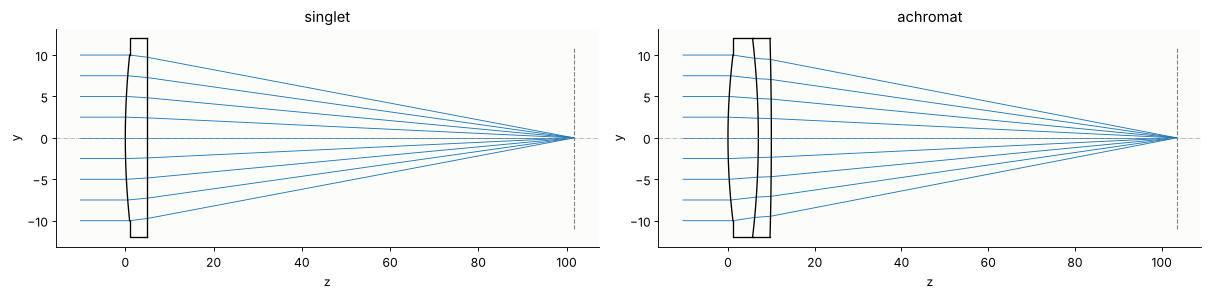

In [4]:
F, EPD = 100.0, 20.0
N_BK7 = float(bk7(WL))


def singlet(K):
    S = [rt.Surface((N_BK7 - 1)*F, 5.0, material=bk7, conic=K, semi_diameter=12.0),
         rt.Surface(np.inf, F, n_after=1.0, semi_diameter=12.0)]
    return rt.System(S, 0, WL*1e-6, entrance_pupil_radius=EPD/2).at_paraxial_focus()


K = brentq(lambda K: singlet(K).trace_pupil(0.0, 0.0, 1.0).points[-1][0, 1], -5, 0)
s1 = singlet(K)

D1 = float(uf.dn_dlambda(bk7, WL))/(N_BK7 - 1)
D2 = float(uf.dn_dlambda(sf6, WL))/(float(sf6(WL)) - 1)
P1 = D2/(D2 - D1)/F
P2 = 1/F - P1
c1 = P1/(N_BK7 - 1)/2
c3 = -c1 - P2/(float(sf6(WL)) - 1)
S = [rt.Surface(1/c1, 7.0, material=bk7, semi_diameter=12.0),
     rt.Surface(-1/c1, 3.0, material=sf6, semi_diameter=12.0),
     rt.Surface(1/c3, F, n_after=1.0, semi_diameter=12.0)]
s2 = rt.System(S, 0, WL*1e-6, entrance_pupil_radius=EPD/2).at_paraxial_focus()
cons = [lo.Constraint(lo.paraxial_value("efl"), F, F, 1e-4, "efl"),
        lo.Constraint(lambda s: lo.focal_shift(790e-6, 810e-6, tolerance=1.0)(s)[0], 0.0, 0.0, 1e-6,
                      "focal shift")]
ops = [lo.ray_errors(fields=(0.0,), rings=(0.3, 0.5, 0.7, 0.85, 1.0), spokes=1, tolerance=1e-4)]
s2 = lo.DampedLeastSquares(s2, lo.curvatures(s2), ops, cons,
                           solves=[lo.solve_paraxial_focus()]).run().system
lenses = {"singlet": s1, "achromat": s2}
print(f"thin lens split: f1 = {1/P1:.1f} mm (N-BK7), f2 = {1/P2:.1f} mm (N-SF6)")
for name, s in lenses.items():
    print(f"{name:>8}: R = {[round(float(x.R), 2) for x in s.surfaces]}, conic {s.surfaces[0].conic:.3f}, "
          f"efl {1/s.power():.3f} mm, dP/dλ = {uf.system_power_derivative(s):.3e} /(mm nm)")

fig, ax = plt.subplots(1, 2, figsize=(15, 3.6), layout="constrained")
for a, (name, s) in zip(ax, lenses.items()):
    s.draw(ax=a, fields=[0.0], n_rays=9)
    a.set_title(name); a.set_aspect("auto")
plt.show()

### Ray-traced delays against Bor's formula

`uf.ray_delays()` traces rays at 800 nm and sums, along each ray, the phase
delay $\sum n_iL_i/c$, the group delay $\sum n_{g,i}L_i/c$ and the GDD
$\sum \text{GVD}_i L_i$ over the media; the group indices and GVDs come from
the indices of the system at neighbouring wavelengths. By Fermat's
principle the paths of the other colours differ only to second order, so the
centre wavelength's rays carry the group delay. The phase delay to the
image plane is constant across the pupil (the lenses focus perfectly at
800 nm), the group delay is not; their difference, relative to the axis, is
Bor's $\Delta T(r)$. The formula uses the traced $dP/d\lambda$ of each
system (`uf.system_power_derivative()`).

 singlet: ΔT at the rim  51.572 fs traced,  51.831 fs Bor; phase delay constant to 15.8 as; GDD axis 223 fs², rim 180 fs²
achromat: ΔT at the rim  -1.661 fs traced,  -0.818 fs Bor; phase delay constant to 677.3 as; GDD axis 900 fs², rim 940 fs²
thin singlet formula -λ dn/dλ r²/(2c(n-1)f): 51.83 fs


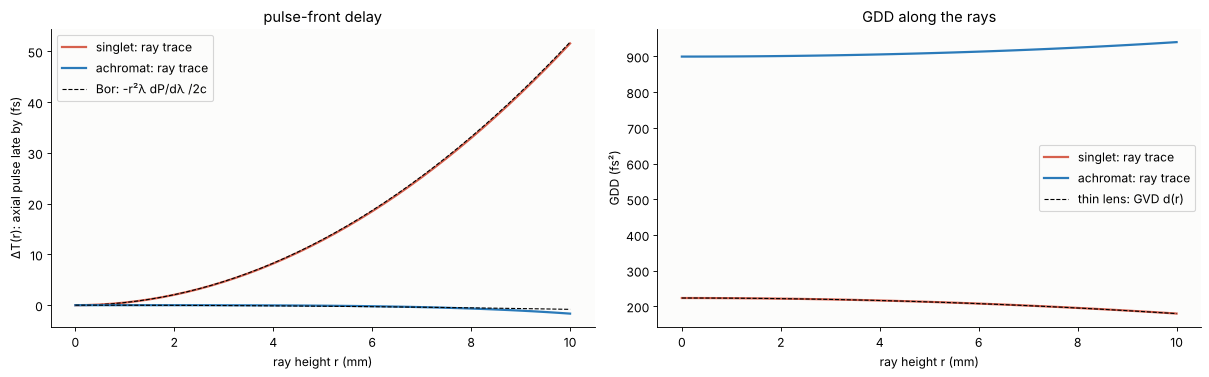

In [5]:
px = np.linspace(0, 1, 41)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
delays = {}
for (name, s), col in zip(lenses.items(), (RED, BLUE)):
    d = uf.ray_delays(s, px)
    delays[name] = d
    lag = d.group - d.phase
    traced = lag[0] - lag
    bor = uf.bor_delay(d.height, WL, uf.system_power_derivative(s))
    ax[0].plot(d.height, traced, color=col, lw=2, label=f"{name}: ray trace")
    ax[0].plot(d.height, bor, color="k", ls="--", lw=1)
    print(f"{name:>8}: ΔT at the rim {traced[-1]:7.3f} fs traced, {bor[-1]:7.3f} fs Bor; "
          f"phase delay constant to {1e3*np.ptp(d.phase):.1f} as; "
          f"GDD axis {d.gdd[0]:.0f} fs², rim {d.gdd[-1]:.0f} fs²")
    ax[1].plot(d.height, d.gdd, color=col, lw=2, label=f"{name}: ray trace")
thin = uf.bor_delay(EPD/2, WL, uf.thin_lens_power_derivative(F, bk7, WL))
print(f"thin singlet formula -λ dn/dλ r²/(2c(n-1)f): {thin:.2f} fs")
gvd_bk7 = float(uf.gvd(bk7, WL))
r = delays["singlet"].height
ax[1].plot(r, gvd_bk7*(delays["singlet"].gdd[0]/gvd_bk7 - r**2/(2*(N_BK7 - 1)*F)), "k--", lw=1,
           label="thin lens: GVD d(r)")
ax[0].plot([], [], "k--", lw=1, label="Bor: -r²λ dP/dλ /2c")
ax[0].set_ylabel("ΔT(r): axial pulse late by (fs)"); ax[0].set_title("pulse-front delay")
ax[1].set_ylabel("GDD (fs²)"); ax[1].set_title("GDD along the rays")
for a in ax:
    a.set_xlabel("ray height r (mm)"); a.legend()
plt.show()

The ray trace follows Bor's formula across the pupil: 51.6 fs at the rim
against 51.8 fs from the thin lens formula (the 5 mm thick lens is a little
weaker at the rim). The phase delay stays constant to a few
attoseconds, so the whole 52 fs is a lag of the pulse behind its phase
front; for a 20 fs pulse that is more than twice its duration. The achromat
cancels the delay to below 2 fs. What remains there grows like $r^4$ and
comes from spherochromatism (the achromat is corrected for colour only in
the paraxial zone), not from the residual $dP/d\lambda$, which the dashed
line shows. (Its phase delay varies by 0.7 fs, a quarter wave of residual
higher order spherical aberration at the paraxial focus.)

The price of the achromat is GDD: with 7 mm of N-BK7 and 3 mm of N-SF6 it
has 900 fs² on the axis, four times the singlet, which would stretch a
20 fs pulse to 126 fs. GDD can be compensated in front of the lens (a prism
or grating compressor, chirped mirrors), the pulse-front delay of a singlet
cannot. The GDD also varies across the pupil: the singlet is thinner at the
rim (dashed: GVD times the thin lens thickness), the achromat thicker in its
flint. This radially varying GDD is the second order partner of Bor's
effect.

## 3. The focus in space and time

### A sum of monochromatic focuses

`uf.focal_spectrum()` traces each lens at 160 wavelengths spanning 640 to
1070 nm. For each wavelength, the exit points of 300 meridional rays carry
the phase $k\,\text{OPL}$, and a Kirchhoff integral over the exit surface,
with the distance to the focal point expanded to first order in the radius
(a Debye type integral), gives the monochromatic field

$$E(r, \omega) = \frac{k}{i}\int A(\rho)\,e^{ikW}J_0\!\left(\frac{k\rho_P r}{D}\right)\frac{\rho\,d\rho}{D},\qquad W = \text{OPL}(P) + D,$$

in the focal plane of the 800 nm focus, $D$ the distance from the exit point
$P$. The absolute phase is kept, so the spectrum carries all group delays
and dispersions of the lens; `uf.to_time()` sums it with the spectrum of a
20 fs Gaussian pulse. Times are counted from the arrival of the pulse
along the axial ray (its group delay `ray_delays(...).group`). With the
"compensated" input, the pulse is prechirped with the negative spectral
phase of the axial glass path (all orders, an ideal pulse shaper), so the
axial ray alone would deliver the transform-limited 20 fs pulse.

At 800 nm the field is the Airy pattern of NA 0.1 (first zero at
$0.61\lambda/\text{NA} = 4.9$ µm).

wavelengths 633 to 1091 nm, 160 traces per lens
first zero at 800 nm: 4.88 µm (Airy: 4.90 µm)
 singlet        as is: peak 0.317 of the ideal focus, FWHM on the axis   35.4 fs
 singlet  compensated: peak 0.304 of the ideal focus, FWHM on the axis   39.8 fs
achromat        as is: peak 0.154 of the ideal focus, FWHM on the axis  129.6 fs
achromat  compensated: peak 0.991 of the ideal focus, FWHM on the axis   20.2 fs


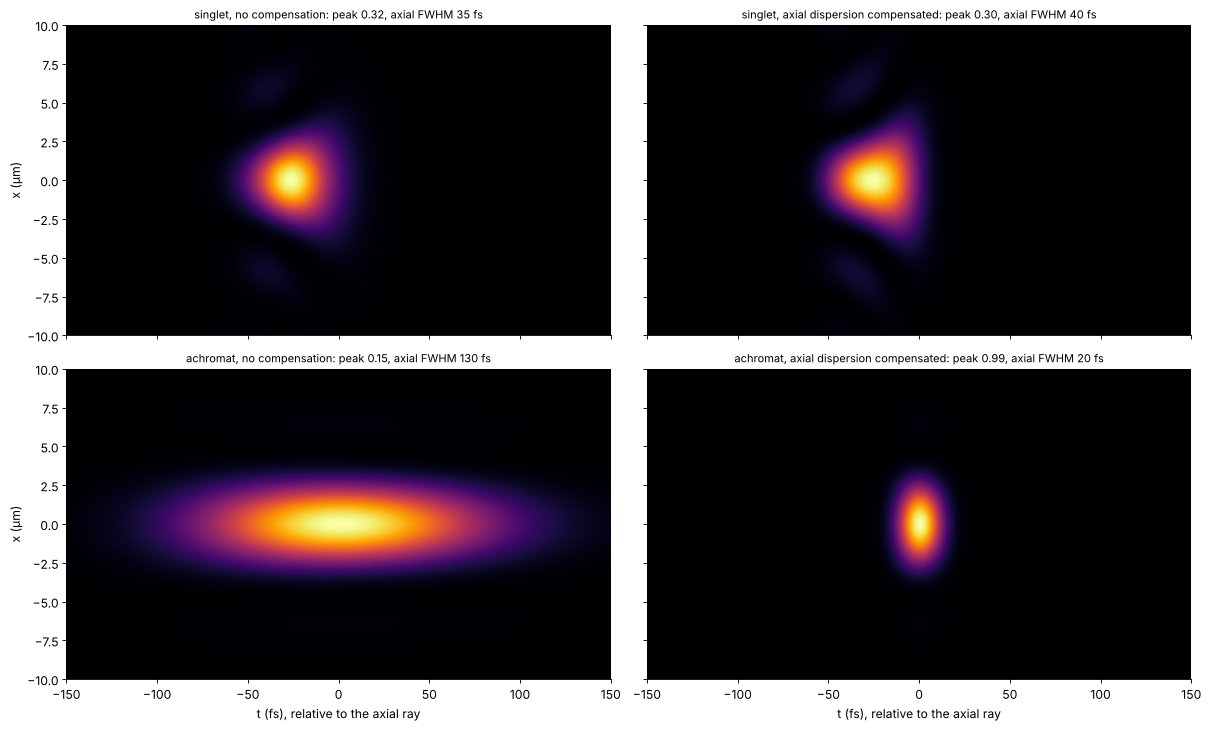

In [6]:
TAU = 20.0
t_f, om_f = uf.pulse_grid(WL, 800.0, 160)
lam_f = uf.wavelength_from_omega(om_f)
r_um = np.linspace(0, 15, 121)
A0 = uf.gaussian_spectrum(om_f, OM0, TAU)
axial_phase = {"singlet": uf.material_phase(bk7, om_f, 5.0, OM0),
               "achromat": uf.material_phase(bk7, om_f, 7.0, OM0) + uf.material_phase(sf6, om_f, 3.0, OM0)}
spectra = {}
for name, s in lenses.items():
    E = uf.focal_spectrum(s, lam_f, r_um*1e-3, n_rho=300)[:, 0, :]
    T0 = uf.ray_delays(s, [0.0]).group[0]
    spectra[name] = E*np.exp(-1j*(om_f - OM0)*T0)[:, None]
print(f"wavelengths {lam_f.min():.0f} to {lam_f.max():.0f} nm, {len(lam_f)} traces per lens")

E800 = spectra["singlet"][80]
I800 = np.abs(E800)**2/np.abs(E800[0])**2
print(f"first zero at 800 nm: {r_um[np.argmin(I800[r_um < 7])]:.2f} µm "
      f"(Airy: {0.61*WL*1e-3/(EPD/2/np.hypot(EPD/2, F)):.2f} µm)")

tt = np.linspace(-150, 150, 601)
cases = {}
for name in lenses:
    for comp in (False, True):
        S = A0*np.exp(-1j*axial_phase[name]) if comp else A0
        Et = uf.to_time(spectra[name]*S[:, None], om_f, tt, OM0, axis=0)
        cases[(name, comp)] = np.abs(Et)**2
# reference: the ideal focus, the achromat's monochromatic foci with their phases removed
# (no delays, no dispersion)
E_perfect = np.abs(spectra["achromat"])
I_perfect = np.abs(uf.to_time(E_perfect*A0[:, None], om_f, tt, OM0, axis=0))**2
peak_ref = I_perfect.max()

fig, ax = plt.subplots(2, 2, figsize=(15, 9), layout="constrained", sharex=True, sharey=True)
x_um = np.r_[-r_um[::-1], r_um[1:]]
for i, name in enumerate(lenses):
    for j, comp in enumerate((False, True)):
        I = cases[(name, comp)]
        I2 = np.c_[I[:, ::-1], I[:, 1:]]
        a = ax[i, j]
        a.imshow(I2.T/I.max(), extent=[tt[0], tt[-1], x_um[0], x_um[-1]], origin="lower",
                 aspect="auto", cmap="inferno", vmin=0, vmax=1)
        a.set_ylim(-10, 10)
        a.set_title(f"{name}, {'axial dispersion compensated' if comp else 'no compensation'}: "
                    f"peak {I.max()/peak_ref:.2f}, axial FWHM {uf.fwhm(tt, I[:, 0]):.0f} fs", fontsize=10)
        print(f"{name:>8} {'compensated' if comp else 'as is':>12}: peak {I.max()/peak_ref:.3f} "
              f"of the ideal focus, FWHM on the axis {uf.fwhm(tt, I[:, 0]):6.1f} fs")
for a in ax[:, 0]:
    a.set_ylabel("x (µm)")
for a in ax[1]:
    a.set_xlabel("t (fs), relative to the axial ray")
plt.show()

The four maps show the focal plane over time, each normalized to its own
peak; the titles give the peak relative to the ideal focus of a 20 fs pulse
(the achromat's monochromatic foci summed without their phases: no delays,
no dispersion). The
singlet's focus starts narrow and ends wide: the rim of the pupil, with
the high NA, arrives up to 52 fs early and makes a narrow spot, the
paraxial zone arrives last and makes a wide one. Compensating the axial GDD
does not help, the delay comes from the geometry of the lens. The achromat
without compensation smears the pulse over about 130 fs by its 900 fs²; with
the compensation its focus is the ideal 20 fs Airy spot (99 % of the ideal
peak), 3.3 times brighter than the singlet.

### On the axis: Bor and Horváth's box

In a uniformly lit pupil equal areas contribute equally to the axial field,
and Bor's delay grows linearly with the area, $s = (r/a)^2$. The axial
field is therefore the pulse averaged over delays spread uniformly between
0 and $\Delta T$, a convolution with a box (Bor and Horváth), times
$\omega$ from the Huygens factor. With the GDD that changes linearly with
$s$ as well (`uf.bor_axis_spectrum()`):

$$E(0, \omega) \propto \omega\,E_\text{in}(\omega)\int_0^1 e^{-i\Omega\Delta T s + i\Omega^2\Delta\text{GDD}\,s/2}\,ds,\qquad \Omega = \omega - \omega_0.$$

In the frequency domain the box is a sinc filter: on the axis the singlet
passes only the colours within about $2\pi/\Delta T$ of 800 nm; the others
are out of focus there (longitudinal chromatic aberration). That is why the
singlet without compensation was shorter on the axis than with it: the
filter narrows the spectrum of the chirped pulse, and a chirped pulse with
less bandwidth is shorter.

axial FWHM,                   box only: 40.03 fs (traced focus 39.83 fs)
axial FWHM, box + radial GDD (-43 fs²): 39.79 fs (traced focus 39.83 fs)
achromat as is: 129.6 fs traced, 126.3 fs Gaussian formula; compensated 20.2 fs


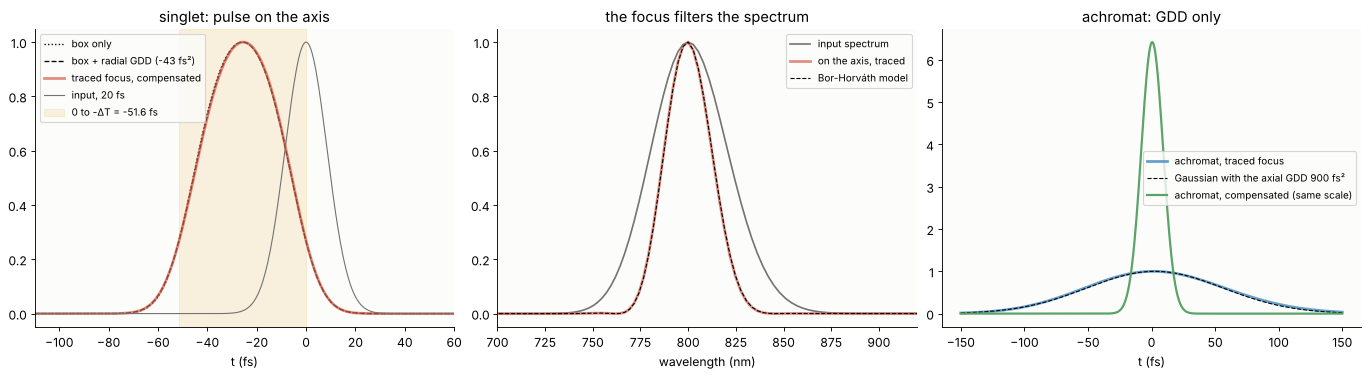

In [7]:
d = delays["singlet"]
lag = d.group - d.phase
dT, dG = lag[0] - lag[-1], d.gdd[-1] - d.gdd[0]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
I_num = cases[("singlet", True)][:, 0]
for dg, ls, lab in ((0.0, ":", "box only"), (dG, "--", f"box + radial GDD ({dG:.0f} fs²)")):
    I_mod = np.abs(uf.to_time(uf.bor_axis_spectrum(om_f, A0, dT, dg), om_f, tt, OM0))**2
    ax[0].plot(tt, I_mod/I_mod.max(), "k", ls=ls, lw=1.2, label=lab)
    print(f"axial FWHM, {lab:>26}: {uf.fwhm(tt, I_mod):.2f} fs (traced focus {uf.fwhm(tt, I_num):.2f} fs)")
ax[0].plot(tt, I_num/I_num.max(), color=RED, lw=2.5, alpha=0.7, label="traced focus, compensated")
I_in = np.abs(uf.to_time(A0, om_f, tt, OM0))**2
ax[0].plot(tt, I_in, color=GREY, lw=1, label="input, 20 fs")
ax[0].axvspan(-dT, 0, color=ORANGE, alpha=0.12, label=f"0 to -ΔT = -{dT:.1f} fs")
ax[0].set_xlim(-110, 60); ax[0].set_xlabel("t (fs)"); ax[0].set_title("singlet: pulse on the axis")
ax[0].legend(fontsize=9)

S_axis = np.abs(spectra["singlet"][:, 0]*A0)**2
S_mod = np.abs(uf.bor_axis_spectrum(om_f, A0, dT, dG))**2
ax[1].plot(lam_f, np.abs(A0)**2/np.abs(A0).max()**2, color=GREY, label="input spectrum")
ax[1].plot(lam_f, S_axis/S_axis.max(), color=RED, lw=2.5, alpha=0.7, label="on the axis, traced")
ax[1].plot(lam_f, S_mod/S_mod.max(), "k--", lw=1, label="Bor-Horváth model")
ax[1].set_xlim(700, 920); ax[1].set_xlabel("wavelength (nm)"); ax[1].set_title("the focus filters the spectrum")
ax[1].legend(fontsize=9)

I_ach = cases[("achromat", False)][:, 0]
gdd_ach = delays["achromat"].gdd[0]
I_g = np.abs(uf.to_time(om_f/OM0*uf.gaussian_spectrum(om_f, OM0, TAU, gdd_ach), om_f, tt, OM0))**2
ax[2].plot(tt, I_ach/I_ach.max(), color=BLUE, lw=2.5, alpha=0.7, label="achromat, traced focus")
ax[2].plot(tt, I_g/I_g.max(), "k--", lw=1, label=f"Gaussian with the axial GDD {gdd_ach:.0f} fs²")
I_c = cases[("achromat", True)][:, 0]
ax[2].plot(tt, I_c/I_ach.max(), color=GREEN, lw=2, label="achromat, compensated (same scale)")
ax[2].set_xlabel("t (fs)"); ax[2].set_title("achromat: GDD only"); ax[2].legend(fontsize=9)
print(f"achromat as is: {uf.fwhm(tt, I_ach):.1f} fs traced, {uf.gaussian_broadening(TAU, gdd_ach):.1f} fs "
      f"Gaussian formula; compensated {uf.fwhm(tt, I_c):.1f} fs")
plt.show()

The traced focus and the box model agree within 0.3 % in duration once the
radially varying GDD is included; the pulse fills the window from
$-\Delta T$ to 0, with its peak in the middle. The axial spectrum
of the traced focus is the narrowed spectrum of the model, with the faint
side lobes of the sinc filter. The achromat's
axial pulse is the Gaussian stretched by its axial GDD (the formula of
section 1, 130 fs against 126 fs; the rest comes from the GDD that grows
towards the rim), and with the axial GDD removed it is a clean 20 fs pulse.

## 4. Pulse-front tilt behind prisms and gratings

### The prism: rays and their group delays

Behind an element with angular dispersion $d\theta/d\lambda$ the pulse
front is tilted against the phase front by

$$\tan\gamma = \lambda\,\frac{d\theta}{d\lambda}$$

(Bor and Rácz; Hebling). For a prism the reason is visible in the rays: the
part of the beam that crosses the thick base lags behind the part near the
apex by $(n_g - n)\Delta L/c$, while the phase fronts stay plane.
`uf.prism_ray_delays()` traces a parallel beam through a 60° N-SF11 prism at
minimum deviation (2D) and sums the phase and group delays from a plane in
front of it to a plane normal to the exit beam. The tilt follows from the
slope of the group delay across the beam, $\tan\gamma = c\,dT_g/dx$; the
formula uses $d\theta/d\lambda = (dn/d\lambda)\sin\alpha/(\cos\theta_1'\cos\theta_2)$
(`uf.prism_dispersion()`).

        prism   θ_in  phase spread   γ rays  γ formula          dθ/dλ
 fused silica  46.6°    1.5e-11 fs   1.153°     1.153°   -0.0252 mrad/nm
        N-BK7  49.1°    1.5e-11 fs   1.388°     1.388°   -0.0303 mrad/nm
       N-SF11  61.9°    4.4e-11 fs   5.687°     5.687°   -0.1245 mrad/nm


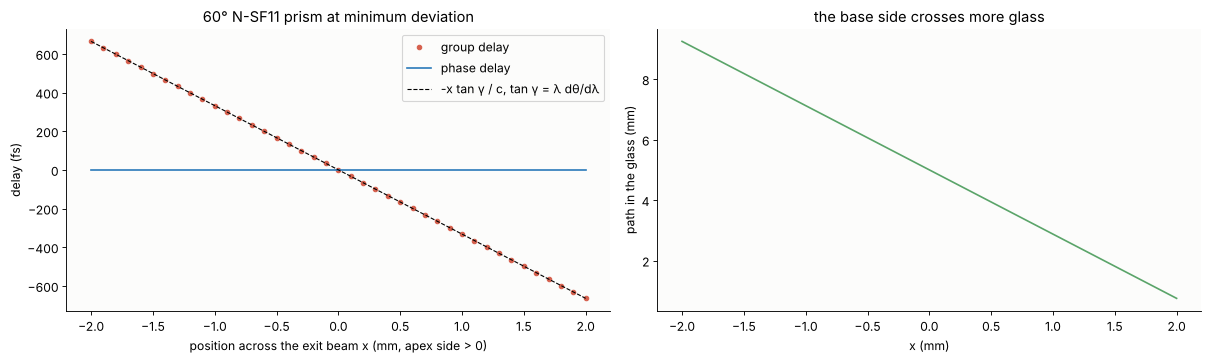

In [8]:
apex = np.deg2rad(60.0)
rows = []
for name in ("fused silica", "N-BK7", "N-SF11"):
    g = glasses[name]
    th = uf.minimum_deviation_incidence(apex, float(g(WL)))
    pd = uf.prism_ray_delays(apex, g, WL, th, np.linspace(-2, 2, 41))
    slope = np.polyfit(pd.x, pd.group, 1)[0]
    D = uf.prism_dispersion(apex, g, WL, th)
    rows.append((name, np.rad2deg(th), np.ptp(pd.phase), np.rad2deg(np.arctan(C*abs(slope))),
                 np.rad2deg(abs(uf.tilt_angle(WL, D))), 1e3*D))
    if name == "N-SF11":
        pd_sf11, th_sf11 = pd, th
print(f"{'prism':>13} {'θ_in':>6} {'phase spread':>13} {'γ rays':>8} {'γ formula':>10} {'dθ/dλ':>14}")
for name, th, ph, gr, gf, D in rows:
    print(f"{name:>13} {th:5.1f}° {ph:10.1e} fs {gr:7.3f}° {gf:9.3f}° {D:9.4f} mrad/nm")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained")
ax[0].plot(pd_sf11.x, pd_sf11.group - pd_sf11.group[20], "o", color=RED, ms=4, label="group delay")
ax[0].plot(pd_sf11.x, pd_sf11.phase - pd_sf11.phase[20], color=BLUE, label="phase delay")
D = uf.prism_dispersion(apex, sf11, WL, th_sf11)
ax[0].plot(pd_sf11.x, -pd_sf11.x*WL*abs(D)/C, "k--", lw=1, label="-x tan γ / c, tan γ = λ dθ/dλ")
ax[0].set_xlabel("position across the exit beam x (mm, apex side > 0)"); ax[0].set_ylabel("delay (fs)")
ax[0].set_title("60° N-SF11 prism at minimum deviation"); ax[0].legend()
ax[1].plot(pd_sf11.x, pd_sf11.glass, color=GREEN)
ax[1].set_xlabel("x (mm)"); ax[1].set_ylabel("path in the glass (mm)")
ax[1].set_title("the base side crosses more glass")
plt.show()

The phase delay is the same for all rays (to $10^{-11}$ fs), the group
delay falls linearly towards the apex, and its slope gives the tilt angle
of the formula to all printed digits: the two are the same statement, one
with rays, one with angles. A 60° N-SF11 prism tilts the pulse front by
5.7°, which across a beam of 4 mm is a delay of 1.3 ps, 65 times the pulse.

### Gratings, and the pulse front seen in $x$–$t$

The same tilt can be seen in a wave picture. In the plane normal to the
central direction, each frequency of the dispersed beam is a plane wave
tilted by $\theta(\omega) - \theta(\omega_0)$; summing them over the spectrum
(`uf.dispersed_beam_xt()`) gives the field $E(x, t)$, whose intensity peak
moves across the beam with the slope $\tan\gamma/c$. For a grating at
normal incidence with $\sin\theta_m = m\lambda/d$ the formula gives
$\tan\gamma = m\lambda/(d\cos\theta_m) = \tan\theta_m$: the pulse front stays
parallel to the grating, as it must, since the pulse hits the whole grating
at once. Gratings tilt far more than prisms.

  60° N-SF11 prism: γ from E(x, t)   5.69°, λ dθ/dλ formula   5.69°


  grating 300 l/mm: γ from E(x, t)  13.89°, λ dθ/dλ formula  13.89°, θ_m = 13.89°


  grating 600 l/mm: γ from E(x, t)  28.69°, λ dθ/dλ formula  28.69°, θ_m = 28.69°


  grating 900 l/mm: γ from E(x, t)  46.02°, λ dθ/dλ formula  46.05°, θ_m = 46.05°


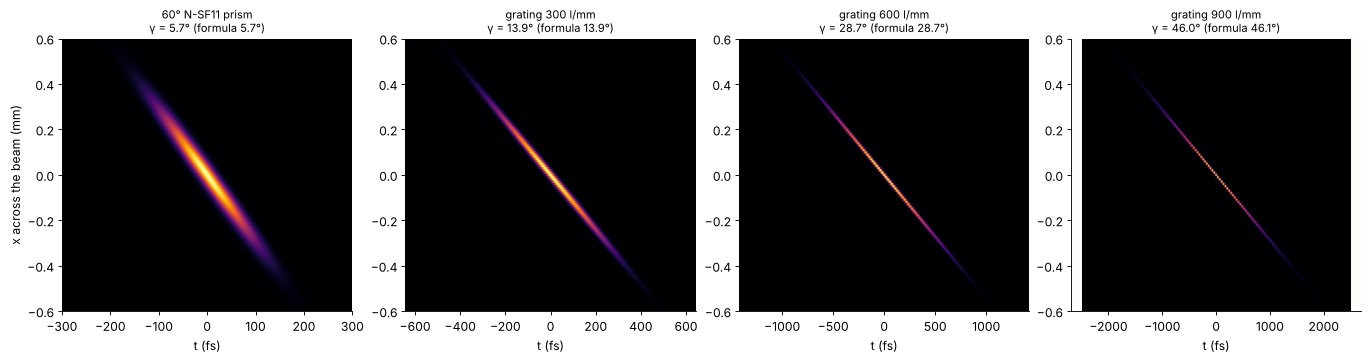

In [9]:
t_x, om_x = uf.pulse_grid(WL, 16000.0, 2048)
A30 = uf.gaussian_spectrum(om_x, OM0, 30.0)
lam_x = uf.wavelength_from_omega(om_x)
elements = {"60° N-SF11 prism": -uf.prism_angles(apex, sf11(lam_x), th_sf11)[2]}
for lines in (300, 600, 900):
    elements[f"grating {lines} l/mm"] = uf.grating_angle(1e6/lines, 1, lam_x)
x = np.linspace(-0.6, 0.6, 121)
tt_x = np.linspace(-2500, 2500, 2501)
fig, ax = plt.subplots(1, 4, figsize=(17, 4.4), layout="constrained")
for a, (name, theta) in zip(ax, elements.items()):
    I = np.abs(uf.dispersed_beam_xt(x, tt_x, om_x, A30, theta, 0.4))**2
    t_peak = tt_x[np.argmax(I, axis=0)]
    g_xt = np.rad2deg(np.arctan(C*abs(np.polyfit(x, t_peak, 1)[0])))
    D = (theta[1025] - theta[1023])/(lam_x[1025] - lam_x[1023])
    g_f = np.rad2deg(abs(uf.tilt_angle(WL, D)))
    extra = ""
    if "grating" in name:
        lines = int(name.split()[1])
        extra = f", θ_m = {np.rad2deg(uf.grating_angle(1e6/lines, 1, WL)):.2f}°"
    print(f"{name:>18}: γ from E(x, t) {g_xt:6.2f}°, λ dθ/dλ formula {g_f:6.2f}°{extra}")
    a.imshow(I.T/I.max(), extent=[tt_x[0], tt_x[-1], x[0], x[-1]], origin="lower", aspect="auto",
             cmap="inferno")
    t_lim = max(300.0, 1.3*x[-1]*np.tan(np.deg2rad(g_f))/C)
    a.set_xlim(-t_lim, t_lim); a.set_xlabel("t (fs)")
    a.set_title(f"{name}\nγ = {g_xt:.1f}° (formula {g_f:.1f}°)", fontsize=10)
ax[0].set_ylabel("x across the beam (mm)")
plt.show()

The intensity ridges of $E(x, t)$ have the slopes of the formula, and for
the gratings the tilt angle equals the diffraction angle. Across a 0.8 mm
wide beam a 30 fs pulse is smeared over 270 fs behind the prism and over
2.8 ps behind the 900 l/mm grating. Pulse-front tilt is useful as well as a
nuisance: tilted pulses pump terahertz generation in lithium niobate
(Hebling), and the angular dispersion of grating and prism pairs is what
compresses pulses (Treacy). Imaged by a lens, angular dispersion turns into
spatial chirp, the starting point of the next section.

## 5. Bonus: simultaneous spatial and temporal focusing

Spread the colours of a pulse across the aperture of a lens: each colour is
a narrow beamlet of radius $w$, centred at $x_c = \alpha\Omega$ on the lens.
Each beamlet alone has a low NA and a long Rayleigh range, but all
beamlets cross in the focus, where the full bandwidth meets and the pulse
is short. Before and behind the focus the beamlets separate, the local
bandwidth shrinks and the pulse stretches. Short pulses, and with them
nonlinear signals such as two-photon fluorescence, are confined to the
focal plane even for a wide field (Zhu et al., Oron et al.).

The model is 1D (a cylindrical lens, $f = 50$ mm), with the exact paraxial
field of each Gaussian beamlet behind the lens from the Collins integral
(`uf.beamlet_focus_1d()`), summed over 256 frequencies of a 30 fs pulse.
The beamlets have $w = 0.4$ mm; the spatial chirp spreads the spectrum
(1/e half width of the field) over $\pm 3$ mm. On the axis at the distance
$z$ from the focus a beamlet is displaced by $-x_c z/f$ and tilted by
$-x_c/f$. Its amplitude there narrows the spectrum, and its tilt and
curvature add a quadratic spectral phase, a GDD:

$$\tau_\text{TL}(z) = \tau\sqrt{1 + \left(\frac{\alpha\Omega_b z}{f\,w(z)}\right)^2},\qquad
\text{GDD}(z) = -\frac{k\alpha^2 z\,z_R^2}{f^2(z^2 + z_R^2)},$$

with $w(z)$ and $z_R$ the radius and Rayleigh range of a focused beamlet.
The axial duration is the Gaussian broadening of section 1 with these two
(`uf.sstf_axis_pulse()`).

beamlet focus: w0 = 31.8 µm, z_R = 3.98 mm; spatial chirp 38.2 mm fs


axial duration, numerics vs closed form: max deviation 0.52 %
pulse twice as long at z = 125 µm (beamlet z_R = 4.0 mm)


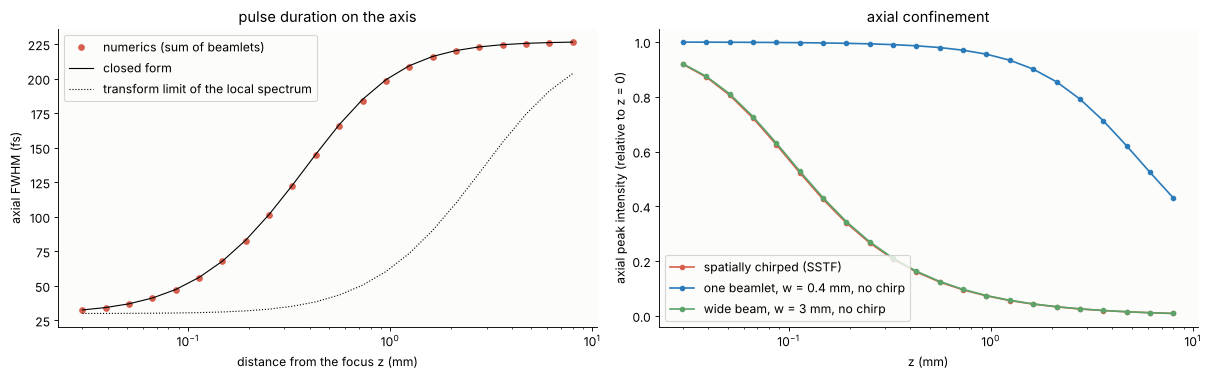

In [10]:
f_s, w_b, tau_s = 50.0, 0.4, 30.0
t_s, om_s = uf.pulse_grid(WL, 4000.0, 256)
lam_s = uf.wavelength_from_omega(om_s)
A_s = uf.gaussian_spectrum(om_s, OM0, tau_s)
omega_b = np.sqrt(8*np.log(2))/tau_s
alpha = 3.0/omega_b                                   # mm per rad/fs
w0 = WL*1e-6*f_s/(np.pi*w_b)
z_r = np.pi*w0**2/(WL*1e-6)
print(f"beamlet focus: w0 = {1e3*w0:.1f} µm, z_R = {z_r:.2f} mm; spatial chirp {alpha:.1f} mm fs")
tt_s = np.linspace(-600, 600, 1201)


def sstf_field(x, z, chirp=alpha, w=w_b):
    E = np.array([uf.beamlet_focus_1d(x, z, l, chirp*(o - OM0), w, f_s) for l, o in zip(lam_s, om_s)])
    E = E*np.exp(-1j*(om_s - OM0)*(f_s + z)/C)[:, None]
    return uf.to_time(E*A_s[:, None], om_s, tt_s, OM0, axis=0)


zs = np.r_[0.0, np.geomspace(0.03, 8.0, 22)]
tau_num, peak_sstf, peak_beamlet, peak_wide = [], [], [], []
for z in zs:
    I_ax = np.abs(sstf_field([0.0], z))[:, 0]**2
    tau_num.append(uf.fwhm(tt_s, I_ax))
    peak_sstf.append(I_ax.max())
    peak_beamlet.append((np.abs(sstf_field([0.0], z, chirp=0.0))[:, 0]**2).max())
    peak_wide.append((np.abs(sstf_field([0.0], z, chirp=0.0, w=3.0))[:, 0]**2).max())
tau_num = np.array(tau_num)
tau_an, tau_tl, gdd_z = uf.sstf_axis_pulse(zs, tau_s, alpha, w_b, f_s, WL)
print(f"axial duration, numerics vs closed form: max deviation {100*np.max(np.abs(tau_num/tau_an - 1)):.2f} %")
zc = brentq(lambda z: uf.sstf_axis_pulse(z, tau_s, alpha, w_b, f_s, WL)[0] - 2*tau_s, 1e-4, 1.0)
print(f"pulse twice as long at z = {1e3*zc:.0f} µm (beamlet z_R = {z_r:.1f} mm)")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
ax[0].semilogx(zs[1:], tau_num[1:], "o", color=RED, ms=5, label="numerics (sum of beamlets)")
ax[0].semilogx(zs[1:], tau_an[1:], "k-", lw=1, label="closed form")
ax[0].semilogx(zs[1:], tau_tl[1:], "k:", lw=1, label="transform limit of the local spectrum")
ax[0].set_xlabel("distance from the focus z (mm)"); ax[0].set_ylabel("axial FWHM (fs)")
ax[0].set_title("pulse duration on the axis"); ax[0].legend()
for p, col, lab in ((peak_sstf, RED, "spatially chirped (SSTF)"),
                    (peak_beamlet, BLUE, "one beamlet, w = 0.4 mm, no chirp"),
                    (peak_wide, GREEN, "wide beam, w = 3 mm, no chirp")):
    p = np.array(p)
    ax[1].semilogx(zs[1:], p[1:]/p[0], "o-", color=col, ms=4, label=lab)
ax[1].set_xlabel("z (mm)"); ax[1].set_ylabel("axial peak intensity (relative to z = 0)")
ax[1].set_title("axial confinement"); ax[1].legend()
plt.show()

The closed form follows the summed beamlets to within a fraction of a
percent. The pulse doubles its length 125 µm from the focus, a thirtieth
of the beamlet's Rayleigh range; most of that is the GDD from the tilt of
the beamlets (dotted: the transform limit of the local spectrum alone grows
much more slowly). Far from the focus the beamlets no longer overlap, the
axis sees the spectrum of a single beamlet and the duration levels off. The peak
intensity of the spatially chirped beam drops as fast as that of the wide,
unchirped beam (NA 0.06), while each beamlet alone has an NA of 0.008.

In the focus the spatial chirp becomes angular dispersion,
$\theta(\Omega) = -\alpha\Omega/f$, so the SSTF focus has a tilted pulse
front with $\tan\gamma = \lambda\,d\theta/d\lambda = \omega_0\alpha/f$.

pulse-front tilt in the focus: 60.9° from E(x, t), 60.9° from ω0 α/f


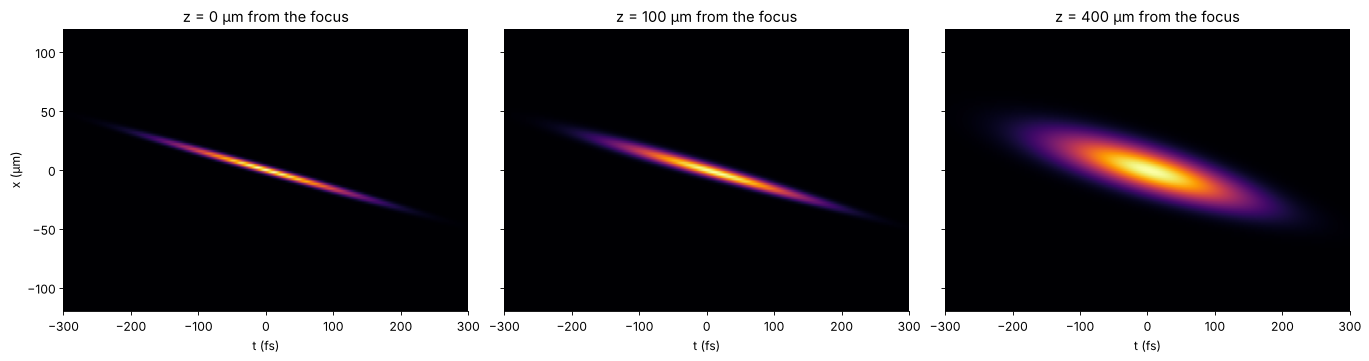

run time: 33 s


In [11]:
x_s = np.linspace(-0.12, 0.12, 121)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), layout="constrained", sharey=True)
for a, z in zip(ax, (0.0, 0.1, 0.4)):
    I = np.abs(sstf_field(x_s, z))**2
    a.imshow(I.T/I.max(), extent=[tt_s[0], tt_s[-1], 1e3*x_s[0], 1e3*x_s[-1]], origin="lower",
             aspect="auto", cmap="inferno")
    a.set_xlim(-300, 300); a.set_xlabel("t (fs)"); a.set_title(f"z = {1e3*z:.0f} µm from the focus")
    if z == 0.0:
        core = np.abs(x_s) < 0.03
        t_peak = tt_s[np.argmax(I, axis=0)]
        g_xt = np.rad2deg(np.arctan(C*abs(np.polyfit(x_s[core], t_peak[core], 1)[0])))
        print(f"pulse-front tilt in the focus: {g_xt:.1f}° from E(x, t), "
              f"{np.rad2deg(np.arctan(OM0*alpha/f_s)):.1f}° from ω0 α/f")
ax[0].set_ylabel("x (µm)")
plt.show()
print(f"run time: {time.time() - t_start:.0f} s")

In the focus the pulse is short on the axis and its front is tilted;
100 µm away it is a longer, chirped streak, and at 400 µm a blob some
200 fs long.

## Summary

- **Dispersion and GDD:** group index, GVD and TOD from any Sellmeier
  formula (`uf.group_index()`, `uf.gvd()`, `uf.tod()`), within 0.01 fs²/mm
  of the published values (N-BK7 44.65, fused silica 36.16 fs²/mm at
  800 nm). Exact numerics through 10 mm of glass follow the Gaussian
  broadening formula to 0.1 % for pulses of 20 fs and longer;
  the best input duration is $\sqrt{4\ln2\,\text{GDD}}$ with a $\sqrt2$
  longer output. Below 10 fs third order dispersion shapes the pulse.
- **Bor's pulse-front delay:** group delays summed along traced rays
  (`uf.ray_delays()`) give 51.6 fs at the rim of an f/5 aspheric N-BK7
  singlet ($f = 100$ mm) against 51.8 fs from
  $\Delta T = -r^2\lambda\,(dP/d\lambda)/2c$ (`uf.bor_delay()`). An
  achromat for 800 nm cancels it to 2 fs (spherochromatism) but has four
  times the GDD (900 fs²).
- **Focus in space and time:** sums of monochromatic focuses from traced
  rays (`uf.focal_spectrum()`, `uf.to_time()`). The singlet's focus spreads
  over $\Delta T$, narrow early (rim) and wide late (centre); on the axis it
  is Bor and Horváth's box average within 0.3 % in duration
  (`uf.bor_axis_spectrum()`), a sinc filter on the spectrum. The achromat
  with its axial GDD compensated gives the ideal 20 fs Airy focus, 3.3 times
  brighter than the singlet.
- **Pulse-front tilt:** rays through a prism have equal phase delays and
  group delays linear across the beam, $\tan\gamma = \lambda\,d\theta/d\lambda$
  to all digits (5.7° for 60° N-SF11); wave synthesis of a dispersed beam
  (`uf.dispersed_beam_xt()`) gives the same for prisms and gratings, where
  $\gamma = \theta_m$ at normal incidence.
- **Spatio-temporal focusing:** a spatially chirped beam focused by a lens
  is short only near the focus; the summed beamlets
  (`uf.beamlet_focus_1d()`) follow the closed form of `uf.sstf_axis_pulse()`
  (local bandwidth and the GDD of the beamlets' tilt), and the axial peak
  falls like that of a beam with the full aperture.

## References

- Z. Bor, "Distortion of femtosecond laser pulses in lenses and lens systems", J. Mod. Opt. 35, 1907-1918 (1988).
- Z. Bor, "Distortion of femtosecond laser pulses in lenses", Opt. Lett. 14, 119-121 (1989).
- Z. Bor and Z. L. Horváth, "Distortion of femtosecond pulses in lenses. Wave optical description", Opt. Commun. 94, 249-258 (1992).
- M. Kempe, U. Stamm, B. Wilhelmi and W. Rudolph, "Spatial and temporal transformation of femtosecond laser pulses by lenses and lens systems", J. Opt. Soc. Am. B 9, 1158-1165 (1992).
- Z. Bor and B. Rácz, "Group velocity dispersion in prisms and its application to pulse compression and travelling-wave excitation", Opt. Commun. 54, 165-170 (1985).
- J. Hebling, "Derivation of the pulse front tilt caused by angular dispersion", Opt. Quantum Electron. 28, 1759-1763 (1996).
- J. Hebling, G. Almási, I. Z. Kozma and J. Kuhl, "Velocity matching by pulse front tilting for large-area THz-pulse generation", Opt. Express 10, 1161-1166 (2002).
- E. B. Treacy, "Optical pulse compression with diffraction gratings", IEEE J. Quantum Electron. 5, 454-458 (1969).
- S. Akturk, X. Gu, P. Gabolde and R. Trebino, "The general theory of first-order spatio-temporal distortions of Gaussian pulses and beams", Opt. Express 13, 8642-8661 (2005).
- G. Zhu, J. van Howe, M. Durst, W. Zipfel and C. Xu, "Simultaneous spatial and temporal focusing of femtosecond pulses", Opt. Express 13, 2153-2159 (2005).
- D. Oron, E. Tal and Y. Silberberg, "Scanningless depth-resolved microscopy", Opt. Express 13, 1468-1476 (2005).
- C. G. Durfee, M. Greco, E. Block, D. Vitek and J. A. Squier, "Intuitive analysis of space-time focusing with double-ABCD calculation", Opt. Express 20, 14244-14259 (2012).
- J.-C. Diels and W. Rudolph, Ultrashort Laser Pulse Phenomena, 2nd ed., Academic Press (2006), chapters 1 and 2.
- I. H. Malitson, "Interspecimen comparison of the refractive index of fused silica", J. Opt. Soc. Am. 55, 1205-1209 (1965).
- I. H. Malitson, "A redetermination of some optical properties of calcium fluoride", Appl. Opt. 2, 1103-1107 (1963).
- M. N. Polyanskiy, "Refractiveindex.info database of optical constants", Sci. Data 11, 94 (2024).
- SCHOTT, "TIE-29: Refractive index and dispersion", technical information (2016).